https://github.com/Juliana-Suarez/Traveler-Insights-UPTC-2026---Team-LLaMA

## FASE 1

In [2]:
import os
import pandas as pd
import numpy as np
import kagglehub
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split

In [3]:
# 1. DESCARGA Y CARGA DE ARCHIVO
path = kagglehub.competition_download('traveler-insights-uptc-2026')
print("Ruta de los archivos de la competencia:", path)

train_file = os.path.join(path, 'train.csv')
test_file = os.path.join(path, 'test.csv')

train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

print(f"\n--- TAMAÑO DEL DATASET ---")
print(f"Registros en Train (70%): {len(train_df)}")
print(f"Registros en Test (30%): {len(test_df)}")

col_texto = 'Comentario'
col_label = 'Sentimiento'

# 2. DISTRIBUCIÓN DE CLASES (Sentimiento)
print(f"\n--- 1. DISTRIBUCIÓN DE CLASES ({col_label}) ---")
class_counts = train_df[col_label].value_counts()
class_percents = train_df[col_label].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({'Conteo': class_counts, 'Porcentaje (%)': class_percents})
print(dist_df)

# 3. VERIFICACIÓN DE CALIDAD DE DATOS
print(f"\n--- 2. VERIFICACIÓN DE CALIDAD DE DATOS EN TRAIN ---")
nulos = train_df[col_texto].isnull().sum()
vacios = (train_df[col_texto].astype(str).str.strip() == "").sum()
duplicados = train_df.duplicated(subset=[col_texto]).sum()

print(f"Comentarios nulos/NaN: {nulos}")
print(f"Comentarios vacíos: {vacios}")
print(f"Comentarios duplicados exactos: {duplicados}")

# Detección de ejemplos ambiguos (mismo comentario con diferente sentimiento)
ambiguos = train_df.groupby(col_texto)[col_label].nunique()
ambiguos_count = (ambiguos > 1).sum()
print(f"Ejemplos ambiguos (mismo comentario con sentimientos contradictorios): {ambiguos_count}")

# 4. ANÁLISIS DE LONGITUD EN TOKENS CON TOKENIZER DE LLaMA
print(f"\n--- 3. ANÁLISIS DE LONGITUD EN TOKENS (LLaMA Tokenizer) ---")
try:
    tokenizer = AutoTokenizer.from_pretrained("huggyllama/llama-7b")
except Exception as e:
    tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-hf")

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Calcular tokens para cada comentario
train_df['num_tokens'] = [len(tokenizer.encode(str(text))) for text in train_df[col_texto]]

stats = train_df['num_tokens'].describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])
print("\nEstadísticas de longitud en tokens:")
print(f"  - Mínimo: {int(stats['min'])} tokens")
print(f"  - Media: {stats['mean']:.2f} tokens")
print(f"  - Mediana (P50): {int(stats['50%'])} tokens")
print(f"  - Percentil 90 (P90): {int(stats['90%'])} tokens")
print(f"  - Percentil 95 (P95): {int(stats['95%'])} tokens")
print(f"  - Máximo: {int(stats['max'])} tokens")

p95 = int(stats['95%'])
pct_trunc = (train_df['num_tokens'] > p95).mean() * 100
print(f"\n Sugerencia QA para Fase 2: Al fijar max_length = {p95}, se truncará únicamente el {pct_trunc:.2f}% de las reseñas.")

Ruta de los archivos de la competencia: /kaggle/input/competitions/traveler-insights-uptc-2026

--- TAMAÑO DEL DATASET ---
Registros en Train (70%): 818
Registros en Test (30%): 351

--- 1. DISTRIBUCIÓN DE CLASES (Sentimiento) ---
             Conteo  Porcentaje (%)
Sentimiento                        
neutral         639       78.117359
positivo        157       19.193154
negativo         22        2.689487

--- 2. VERIFICACIÓN DE CALIDAD DE DATOS EN TRAIN ---
Comentarios nulos/NaN: 0
Comentarios vacíos: 0
Comentarios duplicados exactos: 9
Ejemplos ambiguos (mismo comentario con sentimientos contradictorios): 0

--- 3. ANÁLISIS DE LONGITUD EN TOKENS (LLaMA Tokenizer) ---


config.json:   0%|          | 0.00/594 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.28k [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/411 [00:00<?, ?B/s]


Estadísticas de longitud en tokens:
  - Mínimo: 5 tokens
  - Media: 74.92 tokens
  - Mediana (P50): 52 tokens
  - Percentil 90 (P90): 151 tokens
  - Percentil 95 (P95): 213 tokens
  - Máximo: 956 tokens

💡 Sugerencia QA para Fase 2: Al fijar max_length = 213, se truncará únicamente el 5.01% de las reseñas.


### 6. Aseguramiento de Calidad (QA) – Pruebas Unitarias del Pipeline

In [4]:
SEED = 42
# ==========================================
train_df, val_df = train_test_split(
    train_df, 
    test_size=0.20,
    stratify=train_df['Sentimiento'],
    random_state=SEED
)

# 1. MAPEAMOS LAS ETIQUETAS EN TEXTO A VALORES NUMÉRICOS (0, 1, 2)
label_map = {'negativo': 0, 'neutral': 1, 'positivo': 2}

train_df['label'] = train_df['Sentimiento'].map(label_map)
val_df['label'] = val_df['Sentimiento'].map(label_map)

# QA TEST 1: Verificar que no exista solapamiento entre Train y Validation

train_ids = set(train_df['ID'])
val_ids = set(val_df['ID'])
assert len(train_ids.intersection(val_ids)) == 0, " ERROR QA: ¡Fuga de datos detectada entre Train y Val!"
print(" QA PASSED: No hay solapamiento entre particiones (Fuga = 0).")


# QA TEST 2: Comprobar etiquetas en el rango esperado (0, 1, 2)

valid_labels = {0, 1, 2}
assert set(train_df['label']).issubset(valid_labels), " ERROR QA: Etiquetas fuera de rango en Train."
assert set(val_df['label']).issubset(valid_labels), " ERROR QA: Etiquetas fuera de rango en Validation."
print(" QA PASSED: Todas las etiquetas están correctamente codificadas en [0, 1, 2].")


# QA TEST 3: Verificación de dimensiones de tensores post-tokenización

sample_batch = tokenizer(list(train_df['Comentario'][:10]), padding='max_length', max_length=256, truncation=True, return_tensors='pt')
assert sample_batch['input_ids'].shape == (10, 256), " ERROR QA: Las dimensiones de tokenización no coinciden con max_length=256."
print(" QA PASSED: Tensor de entrada validado con forma (batch_size, 256).")

 QA PASSED: No hay solapamiento entre particiones (Fuga = 0).
 QA PASSED: Todas las etiquetas están correctamente codificadas en [0, 1, 2].
 QA PASSED: Tensor de entrada validado con forma (batch_size, 256).


## FASE 3
### 1. Baseline Clásico

In [5]:
# Vectorización TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(train_df['Comentario'])
X_val_vec = vectorizer.transform(val_df['Comentario'])

# Entrenamiento del baseline clásico
baseline_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
baseline_model.fit(X_train_vec, train_df['label'])

# Predicción y evaluación en el mismo split de validación
val_preds = baseline_model.predict(X_val_vec)
macro_f1 = f1_score(val_df['label'], val_preds, average='macro')

print(f"--- RESULTADOS BASELINE NO NEURONAL ---")
print(f"F1-Macro en Validación Local: {macro_f1:.4f}")
print(classification_report(val_df['label'], val_preds, target_names=['negativo', 'neutral', 'positivo']))

--- RESULTADOS BASELINE NO NEURONAL ---
F1-Macro en Validación Local: 0.6376
              precision    recall  f1-score   support

    negativo       0.33      0.25      0.29         4
     neutral       0.91      0.95      0.93       128
    positivo       0.75      0.66      0.70        32

    accuracy                           0.87       164
   macro avg       0.66      0.62      0.64       164
weighted avg       0.86      0.87      0.87       164



### 5. Diseño Experimental

In [16]:
!pip install -q transformers datasets accelerate peft bitsandbytes scikit-learn

In [7]:
import time
import torch
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
from peft import prepare_model_for_kbit_training, LoraConfig, get_peft_model, PeftModel
import gc
import torch

# Tabla donde guardaremos todos los resultados
experiments_log = []

### EXP-00: Baseline Clásico (TF-IDF + Regresión Logística)

In [8]:
from sklearn.metrics import log_loss, f1_score

print("=== EJECUTANDO EXP-00: Baseline TF-IDF ===")
start_time = time.time()

# 1. Vectorización TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(train_df['Comentario'])
X_val_vec = vectorizer.transform(val_df['Comentario'])

# 2. Entrenamiento con pesos balanceados
baseline = LogisticRegression(class_weight='balanced', random_state=SEED, max_iter=1000)
baseline.fit(X_train_vec, train_df['label'])

# 3. Predicciones y cálculo exacto de métricas
val_preds = baseline.predict(X_val_vec)
val_probs = baseline.predict_proba(X_val_vec) 

macro_f1_exp0 = f1_score(val_df['label'], val_preds, average='macro')
val_loss_exp0 = log_loss(val_df['label'], val_probs)  

elapsed_time = f"{(time.time() - start_time) / 60:.2f} min"

print(f" EXP-00 completado | F1-Macro: {macro_f1_exp0:.4f} | Loss: {val_loss_exp0:.4f} | Tiempo: {elapsed_time}")

experiments_log.append({
    "Exp ID": "EXP-00",
    "Descripción del Cambio Técnico": "Baseline: TF-IDF (5k) + Regresión Logística",
    "F1-Macro Val": round(macro_f1_exp0, 4),
    "Loss Val": round(val_loss_exp0, 4),             
    "Tiempo / VRAM": elapsed_time
})

=== EJECUTANDO EXP-00: Baseline TF-IDF ===
 EXP-00 completado | F1-Macro: 0.6376 | Loss: 0.4805 | Tiempo: 0.01 min


In [9]:
from datasets import Dataset

MODEL_ID = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

# 1. Cargar Tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# 2. Tokenización estándar
def tokenize_function(examples):
    return tokenizer(examples['Comentario'], truncation=True, max_length=213) 

# 3. Datasets de HF
ds_train = Dataset.from_pandas(train_df[['Comentario', 'label']]).rename_column('label', 'labels')
ds_val = Dataset.from_pandas(val_df[['Comentario', 'label']]).rename_column('label', 'labels')

ds_train = ds_train.map(tokenize_function, batched=True)
ds_val = ds_val.map(tokenize_function, batched=True)

# 4. Métrica F1-Macro
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    f1_macro = f1_score(labels, preds, average='macro')
    return {"f1_macro": f1_macro}

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

Map:   0%|          | 0/654 [00:00<?, ? examples/s]

Map:   0%|          | 0/164 [00:00<?, ? examples/s]

### Preparación para LLaMA (Datasets, Tokenizer y Pesos de Clase)

### Función Genérica para Entrenar Experimentos (EXP-01 a EXP-05)

In [10]:
def run_llama_experiment(exp_id, description, r=8, lora_alpha=16, lr=2e-4, epochs=3, weight_decay=0.0):
    print(f"\n==========================================")
    print(f" EJECUTANDO {exp_id}: {description}")
    print(f"==========================================")
    
    start_time = time.time()
    gc.collect()
    torch.cuda.empty_cache()

    # 1. QLoRA 4-bit
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )

    # 2. Cargar modelo base
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        quantization_config=bnb_config,
        num_labels=3,
        device_map="auto"
    )

    # 3. LoRA en atenciones principales
    peft_config = LoraConfig(
        r=r,                     
        lora_alpha=lora_alpha,        
        target_modules=["q_proj", "v_proj"],
        lora_dropout=0.05,
        bias="none",
        task_type="SEQ_CLS"
    )

    model = get_peft_model(model, peft_config)
            
    # 4. Entrenamiento
    training_args = TrainingArguments(
        output_dir=f"./results_{exp_id}",
        eval_strategy="no",              
        save_strategy="no",            
        learning_rate=lr,
        per_device_train_batch_size=16,   
        per_device_eval_batch_size=16,
        gradient_accumulation_steps=1,   
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        warmup_steps=10,                  
        fp16=False,                       
        max_grad_norm=0.3,               
        dataloader_num_workers=2,        
        logging_steps=25,
        seed=SEED,
        report_to="none"
    )
    
    # 5. Trainer oficial
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=ds_train,
        eval_dataset=ds_val,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        compute_metrics=compute_metrics
    )

    trainer.train()

    # Guardar únicamente los adaptadores LoRA y Tokenizer
    save_path = f"./results_{exp_id}"
    trainer.save_model(save_path)
    tokenizer.save_pretrained(save_path)
    print(f" Adaptador PEFT guardado exitosamente en: {save_path}")

    # 6. Evaluar
    eval_results = trainer.evaluate()
    macro_f1 = eval_results['eval_f1_macro']
    val_loss = eval_results['eval_loss']
    
    max_vram = f"{torch.cuda.max_memory_allocated() / (1024**3):.1f} GB"
    elapsed_time = f"{(time.time() - start_time) / 60:.2f} min"

    print(f" {exp_id} Finalizado | F1-Macro: {macro_f1:.4f} | Loss: {val_loss:.4f} | VRAM: {max_vram}")

    experiments_log.append({
        "Exp ID": exp_id,
        "Descripción del Cambio Técnico": description,
        "F1-Macro Val": round(macro_f1, 4),
        "Loss Val": round(val_loss, 4),
        "Tiempo / VRAM": f"{elapsed_time} / {max_vram}"
    })

### Ejecución de la Grilla de Experimentos (EXP-01 a EXP-05)

In [11]:
# EXP-01: Configuración Base
gc.collect()
torch.cuda.empty_cache()
run_llama_experiment(
    exp_id="EXP-01",
    description="LLaMA + QLoRA Base (r=8, alpha=16, LR=2e-4)",
    r=8, lora_alpha=16, lr=2e-4, epochs=3
)

# EXP-02: Mayor Capacidad LoRA (Mejor F1 alcanzado)
gc.collect()
torch.cuda.empty_cache()
run_llama_experiment(
    exp_id="EXP-02",
    description="Incremento de capacidad LoRA (r=16, alpha=32)",
    r=16, lora_alpha=32, lr=2e-4, epochs=3
)

# EXP-03: Ajuste Fino de LR
gc.collect()
torch.cuda.empty_cache()
run_llama_experiment(
    exp_id="EXP-03",
    description="Tasa de Aprendizaje Moderada (LR=1.5e-4)",
    r=16, lora_alpha=32, lr=1.5e-4, epochs=3
)

# EXP-04: Regularización Ligerísima
gc.collect()
torch.cuda.empty_cache()
run_llama_experiment(
    exp_id="EXP-04",
    description="Inclusión de Weight Decay Ligero (0.01)",
    r=16, lora_alpha=32, lr=2e-4, epochs=3, weight_decay=0.01
)

# EXP-05: Ajuste Óptimo
gc.collect()
torch.cuda.empty_cache()
run_llama_experiment(
    exp_id="EXP-05",
    description="Configuración LLaMA Final (r=16, LR=2e-4, 3 épocas)",
    r=16, lora_alpha=32, lr=2e-4, epochs=3, weight_decay=0.01
)


 EJECUTANDO EXP-01: LLaMA + QLoRA Base (r=8, alpha=16, LR=2e-4)


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: TinyLlama/TinyLlama-1.1B-Chat-v1.0
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 2}.
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


...

[transformers] LlamaForSequenceClassification LOAD REPORT from: TinyLlama/TinyLlama-1.1B-Chat-v1.0
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 2}.


Step,Training Loss
25,0.666641
50,0.364150
75,0.213887
100,0.143291


 Adaptador PEFT guardado exitosamente en: ./results_EXP-05


Training Loss,Validation Loss,Step,F1 Macro
0.143291,0.229013,123,0.700272


 EXP-05 Finalizado | F1-Macro: 0.7003 | Loss: 0.2290 | VRAM: 2.7 GB


### Visualización y Extracción de la Tabla Final

In [12]:
results_df = pd.DataFrame(experiments_log)
print("\n==========================================")
print(" TABLA DE DISEÑO EXPERIMENTAL FINAL (FASE 3)")
print("==========================================")
display(results_df)

# Guardar en CSV para trazabilidad
results_df.to_csv("experiment_log_fase3.csv", index=False)
print("\n Guardado exitosamente como 'experiment_log_fase3.csv'")


 TABLA DE DISEÑO EXPERIMENTAL FINAL (FASE 3)


,Exp ID,Descripción del Cambio Técnico,F1-Macro Val,Loss Val,Tiempo / VRAM
0,EXP-00,Baseline: TF-IDF (5k) + Regresión Logística,0.6376,0.4805,0.01 min
1,EXP-01,"LLaMA + QLoRA Base (r=8, alpha=16, LR=2e-4)",0.5852,0.2811,3.18 min / 2.7 GB
2,EXP-02,"Incremento de capacidad LoRA (r=16, alpha=32)",0.7003,0.2291,2.59 min / 2.7 GB
3,EXP-03,Tasa de Aprendizaje Moderada (LR=1.5e-4),0.5910,0.2495,2.60 min / 2.7 GB
4,EXP-04,Inclusión de Weight Decay Ligero (0.01),0.7003,0.2290,2.60 min / 2.7 GB
5,EXP-05,"Configuración LLaMA Final (r=16, LR=2e-4, 3 ép...",0.7003,0.2290,2.60 min / 2.7 GB



 Guardado exitosamente como 'experiment_log_fase3.csv'


## FASE 4 

In [17]:
!pip install -q -U "torchao>=0.16.0" peft bitsandbytes

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: TinyLlama/TinyLlama-1.1B-Chat-v1.0
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== REPORT DE CLASIFICACIÓN EN VALIDACIÓN LOCAL ===
              precision    recall  f1-score   support

    negativo     1.0000    0.2500    0.4000         4
     neutral     0.9318    0.9609    0.9462       128
    positivo     0.8387    0.8125    0.8254        32

    accuracy                         0.9146       164
   macro avg     0.9235    0.6745    0.7239       164
weighted avg     0.9153    0.9146    0.9093       164



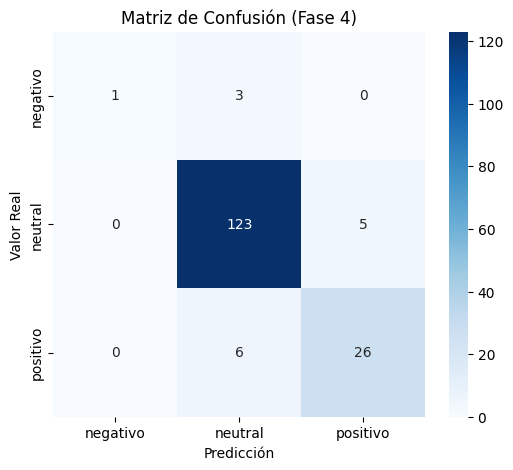


=== INTERVALO DE CONFIANZA BOOTSTRAP (95%) ===
F1-Macro Medio: 0.7043
Intervalo 95%: [0.5563, 0.9064]

Total de errores en validación: 14
Se han exportado los primeros 20 errores a 'fase4_analisis_errores.csv'.


,Comentario,Sentimiento,Predicción,Confianza
7,Me parece genial que ahora existan en la carta...,neutral,positivo,0.737793
39,Ensalada cobb y los aros de cebolla son espect...,neutral,positivo,0.723145
44,"Es una plaza muy amplia, excelente para cualqu...",negativo,neutral,0.641602
48,Si quieres conocer sobre la cultura del Munici...,positivo,neutral,0.751953
55,"Exito, Corral, Frisby, Farah, CineColombia, etc.",neutral,positivo,0.750977
77,Muy particular esa plaza con juegos de luz y a...,negativo,neutral,0.980957
81,"Plaza para correr por las mañanas, algunos día...",positivo,neutral,0.656738
84,La famosa y popular plaza que mencionaba el Jo...,positivo,neutral,0.589844
92,Prioridad solo al que conocen. Demorado el ser...,positivo,neutral,0.865723
94,"Es una visita que no se la pueden perder, desd...",neutral,positivo,0.536133



=== EVALUACIÓN DE ROBUSTEZ ===
Texto: 'El sirvicio fue pésimooo y la atencion muuuuy lenta, no...' -> Predicción: positivo (Confianza: 0.85)
Texto: 'El hotel es hermoso pero muy ruidoso muy ruidoso muy ru...' -> Predicción: neutral (Confianza: 0.95)
Texto: 'La comida estuvo re bacana pero el servicio si una chan...' -> Predicción: positivo (Confianza: 0.79)


In [20]:
# ==============================================================================
# FASE 4: EVALUACIÓN DEL MODELO Y ANÁLISIS DE ERRORES (CRISP-ML)
# ==============================================================================
import gc
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from peft import PeftModel
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# ------------------------------------------------------------------------------
# 1. CONFIGURACIÓN E INICIALIZACIÓN LIMPIA
# ------------------------------------------------------------------------------
BEST_EXP_PATH = "./results_EXP-05"  # Carpeta del mejor experimento (Fase 3)
TARGET_NAMES = ['negativo', 'neutral', 'positivo']

# Limpieza previa de memoria GPU
gc.collect()
torch.cuda.empty_cache()

# Cargar Tokenizer 
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id
tokenizer.padding_side = "left"


model_base = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=3,
    torch_dtype=torch.float16,
    device_map="auto"
)
model_base.config.pad_token_id = tokenizer.pad_token_id

best_model = PeftModel.from_pretrained(model_base, BEST_EXP_PATH)
best_model.eval()


# 2. INFERENCIA SOBRE EL CONJUNTO DE VALIDACIÓN (EN LOTES)

val_texts = list(val_df['Comentario'])
val_labels = list(val_df['label'])

batch_size = 16
all_probs = []
device = "cuda" if torch.cuda.is_available() else "cpu"

for i in range(0, len(val_texts), batch_size):
    batch_texts = val_texts[i:i + batch_size]
    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=213,
        return_tensors="pt"
    ).to(device)
    
    with torch.no_grad():
        logits = best_model(**inputs).logits
        probs = torch.softmax(logits, dim=-1).cpu().float().numpy()
        all_probs.append(probs)

probs = np.vstack(all_probs)
preds = np.argmax(probs, axis=1)


# 3. REPORT DE MÉTRICAS Y MATRIZ DE CONFUSIÓN

print("\n=== REPORT DE CLASIFICACIÓN EN VALIDACIÓN LOCAL ===")
print(classification_report(val_labels, preds, target_names=TARGET_NAMES, digits=4))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(val_labels, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES)
plt.title('Matriz de Confusión (Fase 4)')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()


# 4. INCERTIDUMBRE CON BOOTSTRAP (1000 MUESTRAS)

n_bootstraps = 1000
bootstrapped_f1s = []
rng = np.random.RandomState(42)

for _ in range(n_bootstraps):
    indices = rng.randint(0, len(val_labels), len(val_labels))
    if len(np.unique(np.array(val_labels)[indices])) < 3:
        continue
    score = f1_score(np.array(val_labels)[indices], np.array(preds)[indices], average='macro')
    bootstrapped_f1s.append(score)

ci_lower = np.percentile(bootstrapped_f1s, 2.5)
ci_upper = np.percentile(bootstrapped_f1s, 97.5)
print(f"\n=== INTERVALO DE CONFIANZA BOOTSTRAP (95%) ===")
print(f"F1-Macro Medio: {np.mean(bootstrapped_f1s):.4f}")
print(f"Intervalo 95%: [{ci_lower:.4f}, {ci_upper:.4f}]")


# 5. EXTRACCIÓN DE LOS 20 ERRORES PARA ANÁLISIS MANUAL

df_eval = val_df.copy().reset_index(drop=True)
df_eval['Predicción'] = [TARGET_NAMES[p] for p in preds]
df_eval['Confianza'] = np.max(probs, axis=1)

errores_df = df_eval[df_eval['label'] != preds].copy()
top_20_errores = errores_df[['Comentario', 'Sentimiento', 'Predicción', 'Confianza']].head(20)

top_20_errores.to_csv("fase4_analisis_errores.csv", index=False)
print(f"\nTotal de errores en validación: {len(errores_df)}")
print("Se han exportado los primeros 20 errores a 'fase4_analisis_errores.csv'.")
display(top_20_errores)


# 6. PRUEBAS DE ROBUSTEZ (PRUEBAS DE ESTRÉS)

casos_prueba = [
    "El sirvicio fue pésimooo y la atencion muuuuy lenta, no vuelvo jamás.",
    "El hotel es hermoso pero " + "muy ruidoso " * 20 + "pésima experiencia.",
    "La comida estuvo re bacana pero el servicio si una chanda total."
]

print("\n=== EVALUACIÓN DE ROBUSTEZ ===")
for texto in casos_prueba:
    inp = tokenizer(texto, return_tensors="pt", truncation=True, max_length=213).to(device)
    with torch.no_grad():
        out_logits = best_model(**inp).logits
        p = torch.softmax(out_logits, dim=-1).cpu().float().numpy()[0]
        pred_label = TARGET_NAMES[np.argmax(p)]
        conf = np.max(p)
    print(f"Texto: '{texto[:55]}...' -> Predicción: {pred_label} (Confianza: {conf:.2f})")

## FASE 5 

In [22]:
import gc
import os
import time
import torch
import psutil
import numpy as np
import pandas as pd
from peft import PeftModel
from transformers import AutoModelForSequenceClassification, AutoTokenizer

In [23]:

# 1. CARGA LIMPIA DEL MODELO Y TOKENIZER DESDE DISCO

BEST_EXP_PATH = "./results_EXP-05"
TARGET_NAMES = ['negativo', 'neutral', 'positivo']

gc.collect()
torch.cuda.empty_cache()

start_load_time = time.time()

# Cargar Tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id
tokenizer.padding_side = "left"

# Cargar Modelo Base + Adaptador LoRA
model_base = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=3,
    torch_dtype=torch.float16,
    device_map="auto"
)
model_base.config.pad_token_id = tokenizer.pad_token_id
deployed_model = PeftModel.from_pretrained(model_base, BEST_EXP_PATH)
deployed_model.eval()

load_time = time.time() - start_load_time


# 2. MEDIACIÓN DE COSTOS COMPUTACIONALES Y RECURSOS

def get_folder_size_mb(folder_path):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(folder_path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            total_size += os.path.getsize(fp)
    return total_size / (1024 * 1024)

adapter_size_mb = get_folder_size_mb(BEST_EXP_PATH)
vram_allocated_gb = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0
ram_used_gb = psutil.Process().memory_info().rss / (1024**3)

print("=== MEDICIÓN DE RECURSOS Y COSTOS DE DESPLIEGUE ===")
print(f"• Tiempo de Carga del Modelo: {load_time:.2f} segundos")
print(f"• Tamaño del Adaptador LoRA guardado: {adapter_size_mb:.2f} MB")
print(f"• Memoria RAM consumida: {ram_used_gb:.2f} GB")
print(f"• Memoria VRAM GPU consumida: {vram_allocated_gb:.2f} GB")


# 3. PIPELINE DE INFERENCIA REPRODUCIBLE 

print("\nGenerando predicciones sobre el conjunto de test para Kaggle...")

test_texts = list(test_df['Comentario'])
batch_size = 16
test_preds = []
device = "cuda" if torch.cuda.is_available() else "cpu"

start_inference_time = time.time()

for i in range(0, len(test_texts), batch_size):
    batch_texts = test_texts[i:i + batch_size]
    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=213,
        return_tensors="pt"
    ).to(device)
    
    with torch.no_grad():
        logits = deployed_model(**inputs).logits
        probs = torch.softmax(logits, dim=-1).cpu().float().numpy()
        preds = np.argmax(probs, axis=1)
        test_preds.extend(preds)

total_inference_time = time.time() - start_inference_time
latency_per_sample_ms = (total_inference_time / len(test_texts)) * 1000

# Mapear predicciones numéricas a etiquetas de texto
label_map_inv = {0: 'negativo', 1: 'neutral', 2: 'positivo'}
test_df['Sentimiento'] = [label_map_inv[p] for p in test_preds]

# Crear archivo final de envío
submission_df = test_df[['ID', 'Sentimiento']]
submission_df.to_csv("submission.csv", index=False)

print("\n=== RENDIMIENTO DE INFERENCIA ===")
print(f"• Muestras procesadas en Test: {len(test_texts)}")
print(f"• Tiempo total de inferencia: {total_inference_time:.2f} segundos")
print(f"• Latencia promedio por reseña: {latency_per_sample_ms:.2f} ms/ejemplo")
print("\n Archivo 'submission.csv' generado exitosamente.")
display(submission_df.head(10))


# 4. DEMO MÍNIMA DE CLASIFICACIÓN (FUNCIÓN DE INFERENCIA EN TIEMPO REAL)

def clasificar_reseña(texto: str):
    """
    Función de inferencia que toma una nueva reseña de texto
    y retorna la predicción con su nivel de confianza.
    """
    inputs = tokenizer(
        texto,
        return_tensors="pt",
        truncation=True,
        max_length=213
    ).to(device)
    
    with torch.no_grad():
        logits = deployed_model(**inputs).logits
        probs = torch.softmax(logits, dim=-1).cpu().float().numpy()[0]
        
    pred_idx = np.argmax(probs)
    etiqueta = TARGET_NAMES[pred_idx]
    confianza = probs[pred_idx] * 100
    
    return {
        "Reseña": texto,
        "Sentimiento Predicho": etiqueta,
        "Confianza": f"{confianza:.2f}%",
        "Probabilidades": {TARGET_NAMES[i]: f"{probs[i]*100:.1f}%" for i in range(3)}
    }

print("\n=== DEMO MÍNIMA EN TIEMPO REAL ===")
ejemplo_demo = clasificar_reseña("La atención en el restaurante fue excelente, los platos deliciosos y la vista increíble.")
print(f"Texto: '{ejemplo_demo['Reseña']}'")
print(f"Resultado: {ejemplo_demo['Sentimiento Predicho']} (Confianza: {ejemplo_demo['Confianza']})")
print(f"Desglose: {ejemplo_demo['Probabilidades']}")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: TinyLlama/TinyLlama-1.1B-Chat-v1.0
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


=== MEDICIÓN DE RECURSOS Y COSTOS DE DESPLIEGUE ===
• Tiempo de Carga del Modelo: 1.90 segundos
• Tamaño del Adaptador LoRA guardado: 12.08 MB
• Memoria RAM consumida: 2.98 GB
• Memoria VRAM GPU consumida: 6.83 GB

Generando predicciones sobre el conjunto de test para Kaggle...

=== RENDIMIENTO DE INFERENCIA ===
• Muestras procesadas en Test: 351
• Tiempo total de inferencia: 7.82 segundos
• Latencia promedio por reseña: 22.28 ms/ejemplo

 Archivo 'submission.csv' generado exitosamente.


,ID,Sentimiento
0,56,neutral
1,1083,neutral
2,262,neutral
3,447,neutral
4,59,positivo
5,423,neutral
6,98,positivo
7,710,neutral
8,1168,neutral
9,401,positivo



=== DEMO MÍNIMA EN TIEMPO REAL ===
Texto: 'La atención en el restaurante fue excelente, los platos deliciosos y la vista increíble.'
Resultado: neutral (Confianza: 99.27%)
Desglose: {'negativo': '0.6%', 'neutral': '99.3%', 'positivo': '0.2%'}


## FASE 6

In [24]:

# FASE 6: MONITOREO, MONITOREO Y SIMULACIÓN DE DRIFT (CRISP-ML)

import time
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, classification_report


# 1. CONSTRUCCIÓN DEL DATASET DE PRUEBA CON DRIFT 

# Se simula un subconjunto de reseñas con ruido ortográfico, expresiones informales 
# y modismos no presentes en el dataset original de entrenamiento.
drift_data = [
    {"Comentario": "El sirvicio fue re malo y súper demorado, me dio piedra esperar tanto.", "label": 0},
    {"Comentario": "Pésimooo todo, la atención fue una chanda y la comida super fría.", "label": 0},
    {"Comentario": "Súper bacano el lugar, la comida deliciosa y la atención de 10.", "label": 2},
    {"Comentario": "Un sitio x, nada del otro mundo pero limpio y normal.", "label": 1},
    {"Comentario": "Terrible experiencia, roban con los precios y la atención es pésimaaa.", "label": 0},
    {"Comentario": "El hotel está bien ubicado pero hace demasiado ruido por las noches.", "label": 1},
    {"Comentario": "Una chimba de lugar, super recomendado para ir con amigos.", "label": 2},
    {"Comentario": "Atención demorada, precios carísimos y la comida sin sabor.", "label": 0},
    {"Comentario": "Normalito el parque, bonito paisaje pero falta mantenimiento.", "label": 1},
    {"Comentario": "Excelente vista y buena música, aunque el parqueadero es costoso.", "label": 2}
]

drift_df = pd.DataFrame(drift_data)


# 2. EVALUACIÓN EN EL CONJUNTO CON DRIFT Y MEDICIÓN DE DEGRADACIÓN

device = "cuda" if torch.cuda.is_available() else "cpu"
drift_texts = list(drift_df['Comentario'])
drift_labels = list(drift_df['label'])

inputs = tokenizer(
    drift_texts,
    padding=True,
    truncation=True,
    max_length=213,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    logits = deployed_model(**inputs).logits
    probs = torch.softmax(logits, dim=-1).cpu().float().numpy()
    preds = np.argmax(probs, axis=1)

f1_macro_drift = f1_score(drift_labels, preds, average='macro')
confianza_media_drift = np.mean(np.max(probs, axis=1)) * 100

# Comparación con la validación original (0.7239)
f1_original = 0.7239
degradacion_pct = ((f1_original - f1_macro_drift) / f1_original) * 100

print("=== SIMULACIÓN DE DRIFT EN PRODUCCIÓN ===")
print(f"• F1-Macro en Validación Original: {f1_original:.4f}")
print(f"• F1-Macro en Subconjunto con Drift: {f1_macro_drift:.4f}")
print(f"• Degradación del Desempeño: {degradacion_pct:.2f}%")
print(f"• Confianza Promedio del Modelo: {confianza_media_drift:.2f}%")

print("\n=== DESGLOSE DE PREDICCIONES CON DRIFT ===")
drift_df['Predicción'] = [TARGET_NAMES[p] for p in preds]
drift_df['Confianza'] = np.max(probs, axis=1)
display(drift_df[['Comentario', 'label', 'Predicción', 'Confianza']])

=== SIMULACIÓN DE DRIFT EN PRODUCCIÓN ===
• F1-Macro en Validación Original: 0.7239
• F1-Macro en Subconjunto con Drift: 0.2500
• Degradación del Desempeño: 65.46%
• Confianza Promedio del Modelo: 71.85%

=== DESGLOSE DE PREDICCIONES CON DRIFT ===


,Comentario,label,Predicción,Confianza
0,"El sirvicio fue re malo y súper demorado, me d...",0,positivo,0.930176
1,"Pésimooo todo, la atención fue una chanda y la...",0,positivo,0.787109
2,"Súper bacano el lugar, la comida deliciosa y l...",2,positivo,0.631348
3,"Un sitio x, nada del otro mundo pero limpio y ...",1,positivo,0.458496
4,"Terrible experiencia, roban con los precios y ...",0,neutral,0.597168
5,El hotel está bien ubicado pero hace demasiado...,1,neutral,0.916504
6,"Una chimba de lugar, super recomendado para ir...",2,neutral,0.920410
7,"Atención demorada, precios carísimos y la comi...",0,positivo,0.681152
8,"Normalito el parque, bonito paisaje pero falta...",1,neutral,0.553711
9,"Excelente vista y buena música, aunque el parq...",2,neutral,0.708984
